# Cap. 1-2 · Procesos estocásticos y estacionariedad
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


Cada variable se modela como un proceso estocástico en tiempo discreto $\{X_t\}$. Es **débilmente estacionario** si $E[X_t]=\mu$, $Var(X_t)=\sigma^2$ y $Cov(X_t,X_{t+k})=\gamma(k)$ solo dependen del rezago $k$. La prueba ADF contrasta $H_0$: raíz unitaria.

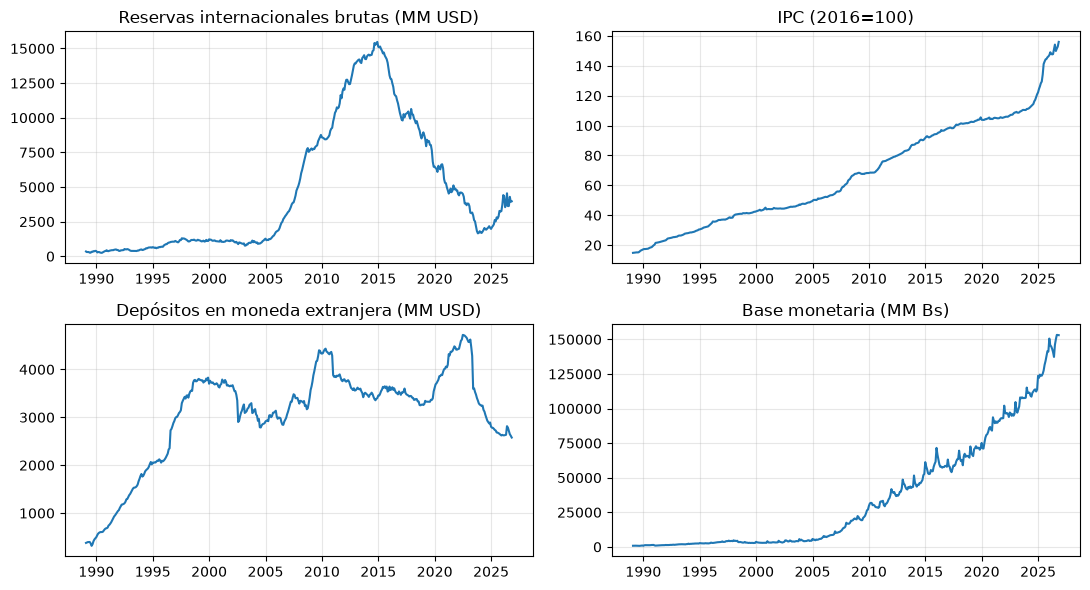

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for a, c in zip(ax.ravel(), ['rib', 'ipc', 'depositos_me', 'base_monetaria']):
    a.plot(m[c].dropna()); a.set_title(data.NOMBRES[c])
plt.tight_layout()

### Momentos muestrales de Δlog(RIB)

In [3]:
dl = np.log(m['rib']).diff().dropna() * 100
mo = stat.sample_moments(dl, 6)
print('media %.3f | varianza %.3f' % (mo['media'], mo['varianza']))
print('autocovarianzas γ(0..6):', np.round(mo['autocovarianzas'], 2))

media 0.539 | varianza 34.412
autocovarianzas γ(0..6): [34.41  2.72  0.57  6.91  3.18  1.48 -2.69]


### Prueba ADF: niveles no estacionarios, diferencias estacionarias

In [4]:
t = stat.adf_table(m, ['rib', 'ipc', 'depositos_me', 'base_monetaria'])
t[t['transformación'].isin(['log', 'Δlog ×100'])].round(3)

,variable,transformación,estadistico,p_valor,rezagos,n,critico_5%,estacionaria_5%
1,rib,log,-1.551,0.508,13,368,-2.869,False
2,rib,Δlog ×100,-2.892,0.046,12,368,-2.869,True
5,ipc,log,0.896,0.993,13,368,-2.869,False
6,ipc,Δlog ×100,-5.428,0.000,12,368,-2.869,True
9,depositos_me,log,-2.822,0.055,4,377,-2.869,False
10,depositos_me,Δlog ×100,-10.368,0.000,1,379,-2.869,True
13,base_monetaria,log,-0.551,0.882,12,369,-2.869,False
14,base_monetaria,Δlog ×100,-3.945,0.002,11,369,-2.869,True


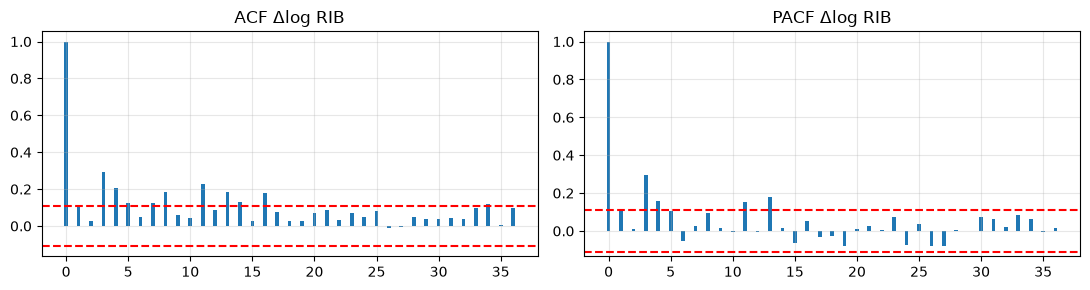

In [5]:
a = stat.acf_pacf(dl['2000':], 36)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].bar(a.lag, a.acf, width=.3); ax[1].bar(a.lag, a.pacf, width=.3)
for x in ax: x.axhline(a.banda95[0], c='r', ls='--'); x.axhline(-a.banda95[0], c='r', ls='--')
ax[0].set_title('ACF Δlog RIB'); ax[1].set_title('PACF Δlog RIB'); plt.tight_layout()